# Superstore Sales & Customer Dataset

### Analysis Project

This project combines a customer information dataset with a sales transaction
dataset, cleans the combined data, and performs exploratory analysis to answer
key business questions about sales, profit, customers, and geography.

**Sections:**
1. Load & Combine Datasets
2. Data Cleaning
3. Exploratory Data Analysis
4. Key Findings & Recommendations

## 1. Load & Combine Datasets

Start with the two raw files:
- `Customers- Dataset.csv` — one row per customer (demographics, location)
- `Sales - dataset1.csv` — one row per order line (product, sales, profit)

They share a common key: `Customer ID` (customers file) / `CustomerID` (sales file).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
# Load the data
customers = pd.read_csv("C:/Users/hp/Documents/Python For Data Analyst and Data Apps/Project/Superstore sales & customers Analysis/data/Customers- Dataset.csv")
sales = pd.read_csv("C:/Users/hp/Documents/Python For Data Analyst and Data Apps/Project/Superstore sales & customers Analysis/data/Sales - dataset1.csv")

print("Customers:", customers.shape)
print("Sales:", sales.shape)

Customers: (793, 9)
Sales: (9931, 13)


In [3]:
customers.head()

,Customer ID,Customer Name,Segment,Age,Country,City,State,Postal Code,Region
0,CG-12520,Claire Gute,Consumer,107,United States,Henderson,Kentucky,42420,South
1,DV-13045,Darrin Van Huff,Corporate,31,United States,Los Angeles,California,90036,West
2,SO-20335,Sean O'Donnell,Consumer,65,United States,Fort Lauderdale,Florida,33311,South
3,BH-11710,Brosina Hoffman,Consumer,20,United States,Los Angeles,California,90032,West
4,AA-10480,Andrew Allen,Consumer,50,United States,Concord,North Carolina,28027,South


In [4]:
sales.head()

,OrderLine,OrderID,OrderDate,ShipDate,ShipMode,CustomerID,ProductID,Category,SubCategory,Sales,Quantity,Discount,Profit
0,64,CA-2015-135545,11/24/2015,11/30/2015,Standard Class,KM-16720,OFF-BI-10001078,Office Supplies,Binders,USD25.82,6,0.2,9.36
1,65,CA-2015-135545,11/24/2015,11/30/2015,Standard Class,KM-16720,OFF-PA-10003892,Office Supplies,Paper,USD146.73,3,0.0,68.96
2,66,CA-2015-135545,11/24/2015,11/30/2015,Standard Class,KM-16720,FUR-FU-10000397,Furniture,Furnishings,USD79.76,4,0.0,22.33
3,67,US-2015-164175,4/30/2015,05/05/2015,Standard Class,PS-18970,FUR-CH-10001146,Furniture,Chairs,USD213.12,5,0.3,-15.22
4,68,CA-2014-106376,12/05/2014,12/10/2014,Standard Class,BS-11590,OFF-AR-10002671,Office Supplies,Art,USD1113.02,8,0.2,111.30


### Verifying the join key before merging

Before merging, we check that the ID columns actually line up between the two files, otherwise a merge could silently drop or duplicate rows.

In [5]:
# Check the join keys match before merging
# Customers file uses "Customer ID", Sales file uses "CustomerID"
cust_ids = set(customers["Customer ID"])
sales_ids = set(sales["CustomerID"])

print(f"Unique customers:", len(cust_ids))
print(f"Unique CustomerIDs referenced in sales:", len(sales_ids))
print(f"Sales IDs missing from Customers file:", len(sales_ids - cust_ids))
print(f"Customers with no sales:", len(cust_ids - sales_ids))
print(f"Duplicate Customer IDs in Customers file:", customers["Customer ID"].duplicated().sum())

Unique customers: 793
Unique CustomerIDs referenced in sales: 793
Sales IDs missing from Customers file: 0
Customers with no sales: 0
Duplicate Customer IDs in Customers file: 0


Every sales record has a matching customer and there are no duplicate customer IDs, so this is a clean one-to-many relationship (one customer -> many orders).
A **left merge** on the sales file preserves every order line.

In [6]:
df = sales.merge(
    customers,
    left_on="CustomerID",
    right_on="Customer ID",
    how="left"
)

assert df.shape[0] == sales.shape[0], "Row count changed during merge!"
print("Combined dataset:", df.shape)
df.head()

Combined dataset: (9931, 22)


,OrderLine,OrderID,OrderDate,ShipDate,ShipMode,CustomerID,ProductID,Category,SubCategory,Sales,Quantity,Discount,Profit,Customer ID,Customer Name,Segment,Age,Country,City,State,Postal Code,Region
0,64,CA-2015-135545,11/24/2015,11/30/2015,Standard Class,KM-16720,OFF-BI-10001078,Office Supplies,Binders,USD25.82,6,0.2,9.36,KM-16720,Kunst Miller,Consumer,69,United States,Los Angeles,California,90004,West
1,65,CA-2015-135545,11/24/2015,11/30/2015,Standard Class,KM-16720,OFF-PA-10003892,Office Supplies,Paper,USD146.73,3,0.0,68.96,KM-16720,Kunst Miller,Consumer,69,United States,Los Angeles,California,90004,West
2,66,CA-2015-135545,11/24/2015,11/30/2015,Standard Class,KM-16720,FUR-FU-10000397,Furniture,Furnishings,USD79.76,4,0.0,22.33,KM-16720,Kunst Miller,Consumer,69,United States,Los Angeles,California,90004,West
3,67,US-2015-164175,4/30/2015,05/05/2015,Standard Class,PS-18970,FUR-CH-10001146,Furniture,Chairs,USD213.12,5,0.3,-15.22,PS-18970,Paul Stevenson,Home Office,31,United States,Chicago,Illinois,60610,Central
4,68,CA-2014-106376,12/05/2014,12/10/2014,Standard Class,BS-11590,OFF-AR-10002671,Office Supplies,Art,USD1113.02,8,0.2,111.30,BS-11590,Brendan Sweed,Corporate,45,United States,Gilbert,Arizona,85234,West


In [7]:
# Load the combined dataset
df = pd.read_csv("C:/Users/hp/Documents/Python For Data Analyst and Data Apps/Project/Superstore sales & customers Analysis/data/combined_dataset.csv")


## 2. Data Cleaning

### 2.1 Drop the redundant join key

`Customer ID` (from the customers file) is identical in content to `CustomerID`(from the sales file), it only exists because of the merge. Keeping both is redundant and can cause confusion later, so we drop one.

In [8]:
df = sales.merge(
    customers,
    left_on="CustomerID",
    right_on="Customer ID",
    how="left"
)

assert df.shape[0] == sales.shape[0], "Row count changed during merge!"
print("Combined dataset:", df.shape)
df.head()

Combined dataset: (9931, 22)


,OrderLine,OrderID,OrderDate,ShipDate,ShipMode,CustomerID,ProductID,Category,SubCategory,Sales,Quantity,Discount,Profit,Customer ID,Customer Name,Segment,Age,Country,City,State,Postal Code,Region
0,64,CA-2015-135545,11/24/2015,11/30/2015,Standard Class,KM-16720,OFF-BI-10001078,Office Supplies,Binders,USD25.82,6,0.2,9.36,KM-16720,Kunst Miller,Consumer,69,United States,Los Angeles,California,90004,West
1,65,CA-2015-135545,11/24/2015,11/30/2015,Standard Class,KM-16720,OFF-PA-10003892,Office Supplies,Paper,USD146.73,3,0.0,68.96,KM-16720,Kunst Miller,Consumer,69,United States,Los Angeles,California,90004,West
2,66,CA-2015-135545,11/24/2015,11/30/2015,Standard Class,KM-16720,FUR-FU-10000397,Furniture,Furnishings,USD79.76,4,0.0,22.33,KM-16720,Kunst Miller,Consumer,69,United States,Los Angeles,California,90004,West
3,67,US-2015-164175,4/30/2015,05/05/2015,Standard Class,PS-18970,FUR-CH-10001146,Furniture,Chairs,USD213.12,5,0.3,-15.22,PS-18970,Paul Stevenson,Home Office,31,United States,Chicago,Illinois,60610,Central
4,68,CA-2014-106376,12/05/2014,12/10/2014,Standard Class,BS-11590,OFF-AR-10002671,Office Supplies,Art,USD1113.02,8,0.2,111.30,BS-11590,Brendan Sweed,Corporate,45,United States,Gilbert,Arizona,85234,West


In [9]:
df = df.drop(columns=["Customer ID"])
df.columns.tolist()

['OrderLine',
 'OrderID',
 'OrderDate',
 'ShipDate',
 'ShipMode',
 'CustomerID',
 'ProductID',
 'Category',
 'SubCategory',
 'Sales',
 'Quantity',
 'Discount',
 'Profit',
 'Customer Name',
 'Segment',
 'Age',
 'Country',
 'City',
 'State',
 'Postal Code',
 'Region']

### 2.2 Fix data types: `Sales` stored as text

The `Sales` column contains values like `"USD25.82"` instead of a number, which means pandas reads it as text (`object`). This blocks any arithmetic,
aggregation, or plotting on sales figures until it's fixed.

In [10]:
print(f"Before:", df["Sales"].dtype)
print(df["Sales"].head(3).tolist())

df["Sales"] = df["Sales"].str.replace("USD", "", regex=False).astype(float)

print("After:", df["Sales"].dtype)
df["Sales"].describe()

Before: str
['USD25.82', 'USD146.73', 'USD79.76']
After: float64


count     9931.000000
mean       229.611947
std        623.930052
min          0.440000
25%         17.265000
50%         54.380000
75%        209.905000
max      22638.480000
Name: Sales, dtype: float64

### 2.3 Fix data types: Parse dates

`OrderDate` and `ShipDate` are stored as text strings (with inconsistent
zero-padding, e.g. `"4/30/2015"` vs `"11/24/2015"`). Converting them to real datetime objects is necessary for any time-based analysis.

In [11]:
df["OrderDate"] = pd.to_datetime(df["OrderDate"], format="%m/%d/%Y")
df["ShipDate"] = pd.to_datetime(df["ShipDate"], format="%m/%d/%Y")

df[["OrderDate", "ShipDate"]].dtypes

OrderDate    datetime64[us]
ShipDate     datetime64[us]
dtype: object

### 2.4 Inconsistent categorical values - `Country`

The `Country` column uses two different labels for the same country: `"US"`and `"United States"`. If left unfixed, any grouping or filtering by country would incorrectly treat these as two separate countries.

In [12]:
print("Before:")
print(df["Country"].value_counts())

df["Country"] = df["Country"].replace({"US": "United States"})

print("\nAfter:")
print(df["Country"].value_counts())

Before:
Country
United States    9861
US                 70
Name: count, dtype: int64

After:
Country
United States    9931
Name: count, dtype: int64


### 2.5 Invalid values, `Age` outliers

A quick check of `Age` reveals values like 107, 400, and 1000 biologically
impossible ages, almost certainly data-entry errors (e.g. an extra digit typed in). Leaving these in would badly skew any age-based averages or segmentation.

We treat anything above 100 as invalid. Rather than guessing a "corrected" value, we set these to missing (`NaN`), since there's no reliable way to recover the true age.

In [13]:
print("Age summary before cleaning:")
print(df["Age"].describe())

suspicious = df.loc[df["Age"] > 100, ["CustomerID", "Customer Name", "Age"]].drop_duplicates()
print("\nSuspicious records:")
print(suspicious)

df.loc[df["Age"] > 100, "Age"] = np.nan

print("\nAge summary after cleaning:")
print(df["Age"].describe())

Age summary before cleaning:
count    9931.000000
mean       45.980163
std        33.564957
min        18.000000
25%        31.000000
50%        45.000000
75%        59.000000
max      1000.000000
Name: Age, dtype: float64

Suspicious records:
     CustomerID      Customer Name   Age
98     EM-13960       Eric Murdock  1000
132    CB-12025  Cassandra Brandow   400
5428   CG-12520        Claire Gute   107

Age summary after cleaning:
count    9896.000000
mean       44.453112
std        15.682068
min        18.000000
25%        31.000000
50%        45.000000
75%        59.000000
max        70.000000
Name: Age, dtype: float64


### 2.6 Missing values

We now check the full dataset for missing values (including the `Age` values we just nulled out) and decide how to handle each.

In [14]:
missing = df.isna().sum()
missing = missing[missing > 0]
print(missing)

Age    35
dtype: int64


`Age` is the only column with missing values, and only because we intentionally nulled out invalid entries in the previous step. We leave these as `NaN` (rather than dropping the rows or imputing a guessed value), because:
- Dropping rows would lose valid sales/profit data for those orders.
- Imputing a fake age (e.g. the mean) would misrepresent real customers.

Any analysis that uses `Age` will simply exclude these rows automatically via pandas' default `NaN` handling.

### 2.7 Duplicate rows

Finally, we check for fully duplicated rows in the combined dataset these
would indicate the same order line was recorded (or merged) more than once.

In [15]:
duplicate = df.duplicated().sum()
print("Fully duplicated rows:", duplicate)

if duplicate > 0:
    df = df.drop_duplicates()
    print("Duplicates removed. New shape:", df.shape)
else:
    print("No duplicate rows found — nothing to remove.")

Fully duplicated rows: 0
No duplicate rows found — nothing to remove.


### 2.8 Final check & save cleaned dataset

In [16]:
print("Final shape:", df.shape)
print(df.dtypes)

df.to_csv("C:/Users/hp/Documents/Python For Data Analyst and Data Apps/Project/Superstore sales & customers Analysis/data/Superstore Sales & Customer Dataset.csv", index=False)
print("\nSaved cleaned dataset.")

Final shape: (9931, 21)
OrderLine                 int64
OrderID                     str
OrderDate        datetime64[us]
ShipDate         datetime64[us]
ShipMode                    str
CustomerID                  str
ProductID                   str
Category                    str
SubCategory                 str
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
Customer Name               str
Segment                     str
Age                     float64
Country                     str
City                        str
State                       str
Postal Code               int64
Region                      str
dtype: object

Saved cleaned dataset.


### Summary of cleaning steps

| # | Issue | Fix | Why |
|---|-------|-----|-----|
| 1 | Redundant join column | Dropped duplicate `Customer ID` | Avoid confusion, no information lost |
| 2 | `Sales` stored as text (`"USD25.82"`) | Stripped prefix, converted to float | Enables arithmetic/aggregation |
| 3 | Dates stored as text | Parsed to datetime | Enables time-based analysis |
| 4 | Inconsistent `Country` labels | Standardized "US" -> "United States" | Correct grouping/filtering |
| 5 | Impossible `Age` values (107, 400, 1000) | Set to `NaN` | Prevents skewed statistics |
| 6 | Missing values | Left as `NaN`, excluded automatically in aggregations | No reliable way to recover true values |
| 7 | Duplicate rows | Checked and no duplicates found | Avoid double-counting sales |


## 3. Exploratory Data Analysis(EDA)

With the data cleaned, we can now explore sales performance, profitability, customers, and geography.

### 3.1 Overall performance

In [17]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["OrderID"].nunique()
avg_order_value = df.groupby("OrderID")["Sales"].sum().mean()

print(f"Total Sales:   ${total_sales:,.2f}")
print(f"Total Profit:  ${total_profit:,.2f}")
print(f"Overall Margin:  {total_profit/total_sales:.1%}")
print(f"Total Orders:    {total_orders:,}")
print(f"Avg. Order Value: ${avg_order_value:,.2f}")

Total Sales:   $2,280,276.25
Total Profit:  $286,956.82
Overall Margin:  12.6%
Total Orders:    4,982
Avg. Order Value: $457.70


### 3.2 Sales & Profit by Category

In [18]:
cat_summary = df.groupby("Category")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
cat_summary["Margin %"] = cat_summary["Profit"] / cat_summary["Sales"] * 100
print(cat_summary)

                     Sales     Profit   Margin %
Category                                        
Technology       831228.89  144748.05  17.413741
Furniture        732618.89   20066.52   2.739012
Office Supplies  716428.47  122142.25  17.048771


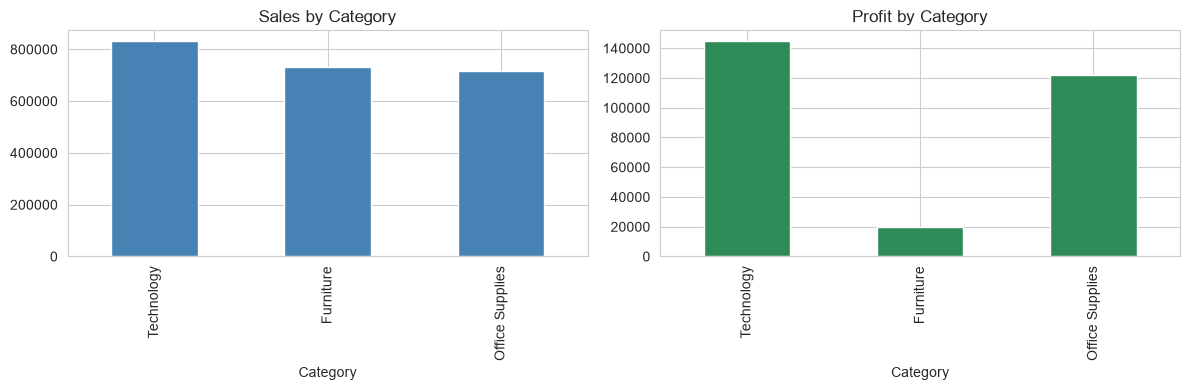

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
cat_summary["Sales"].plot(kind="bar", ax=ax[0], title="Sales by Category", color="steelblue")
cat_summary["Profit"].plot(kind="bar", ax=ax[1], title="Profit by Category", color="seagreen")

plt.tight_layout()
plt.savefig('Sales & Profit.png')
plt.show()

### 3.3 Profit by Sub-Category 

Why is money being lost?

                 Sales    Profit
SubCategory                     
Tables       203257.29 -17668.13
Bookcases    111002.26  -1802.44
Supplies      46673.52  -1188.99
Fasteners      3008.99    943.27
Machines     189238.68   3384.73
Labels        12396.50   5503.98
Art           26979.76   6504.35
Envelopes     16359.79   6927.58
Furnishings   91334.98  13174.55
Appliances   107288.09  18211.77
Storage      222505.82  21179.15
Chairs       327024.36  26362.54
Binders      202828.74  30045.73
Paper         78387.26  34015.41
Accessories  167154.78  41890.84
Phones       325307.42  43854.58
Copiers      149528.01  55617.90


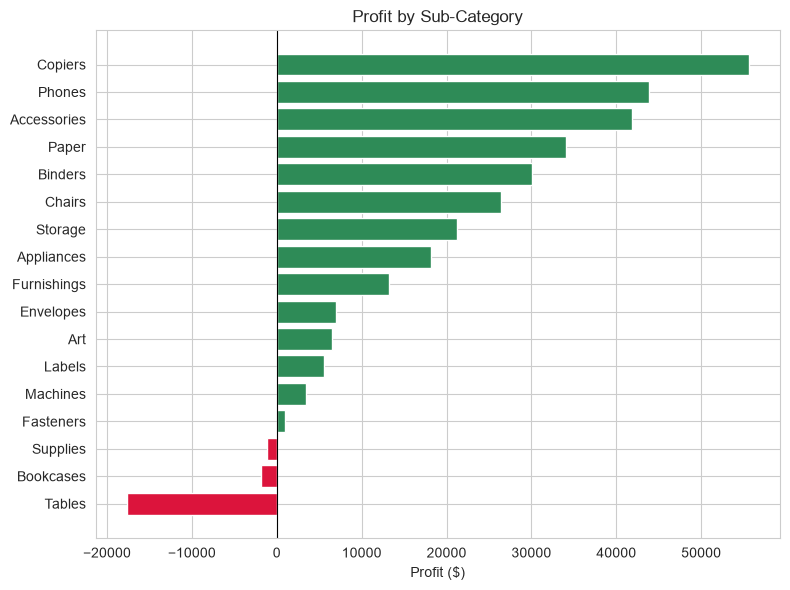

In [28]:
sub_summary = df.groupby("SubCategory")[["Sales", "Profit"]].sum().sort_values("Profit")
print(sub_summary)

plt.figure(figsize=(8, 6))
colors = sub_summary["Profit"].apply(lambda x: "crimson" if x < 0 else "seagreen")
plt.barh(sub_summary.index, sub_summary["Profit"], color=colors)
plt.title("Profit by Sub-Category")
plt.xlabel("Profit ($)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.savefig('Profit_by_subcategory.png')
plt.show()

### 3.4 Does discount level affect profit?

Discount
(-0.01, 0.0]     67.097896
(0.0, 0.1]       97.011935
(0.1, 0.2]       24.689761
(0.2, 0.3]      -46.014089
(0.3, 0.4]     -109.488190
(0.4, 0.5]     -279.354000
(0.5, 1.0]      -89.624935
Name: Profit, dtype: float64


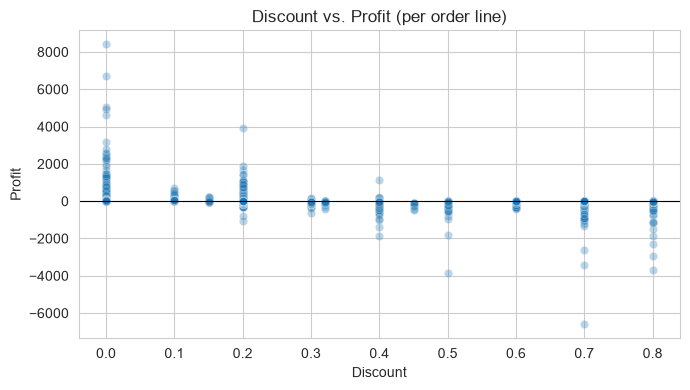

In [29]:
discount_profit = df.groupby(pd.cut(df["Discount"], bins=[-0.01,0,0.1,0.2,0.3,0.4,0.5,1]))["Profit"].mean()
print(discount_profit)

plt.figure(figsize=(7,4))
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.3)
plt.title("Discount vs. Profit (per order line)")
plt.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.savefig('Discount_vs_profit.png')
plt.show()

### 3.5 Sales trend over time

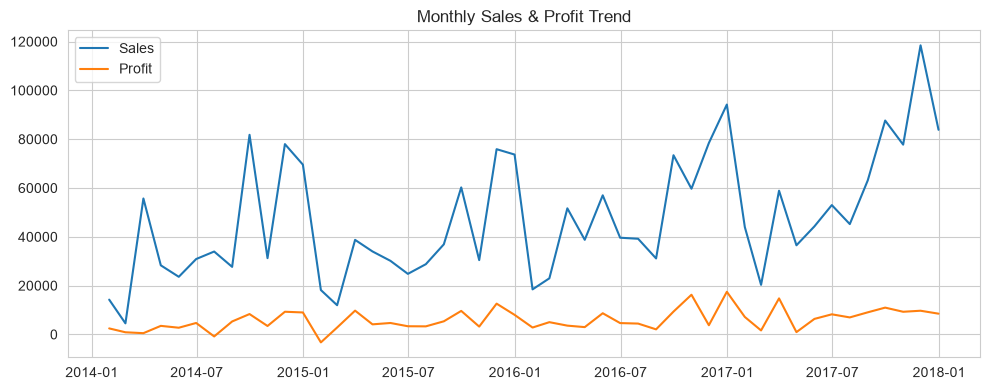

In [30]:
monthly = df.set_index("OrderDate").resample("ME")[["Sales", "Profit"]].sum()

plt.figure(figsize=(10,4))
plt.plot(monthly.index, monthly["Sales"], label="Sales")
plt.plot(monthly.index, monthly["Profit"], label="Profit")
plt.legend()
plt.title("Monthly Sales & Profit Trend")
plt.tight_layout()
plt.savefig('Sales_trend_over_time.png')
plt.show()

### 3.6 Customer Segments

                  Sales     Profit   Margin %
Segment                                      
Consumer     1148618.50  134941.75  11.748178
Corporate     703334.24   91613.38  13.025582
Home Office   428323.51   60401.69  14.101885


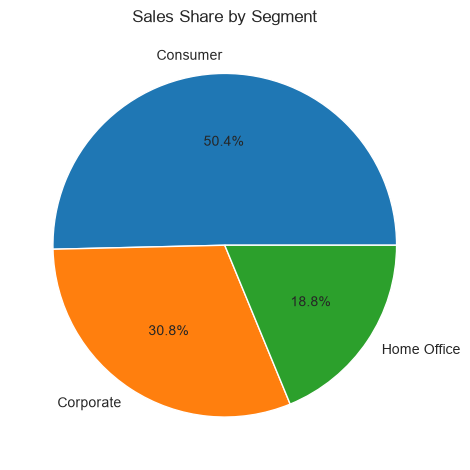

In [31]:
seg_summary = df.groupby("Segment")[["Sales","Profit"]].sum()
seg_summary["Margin %"] = seg_summary["Profit"]/seg_summary["Sales"]*100
print(seg_summary)

seg_summary["Sales"].plot(kind="pie", autopct="%1.1f%%", ylabel="")
plt.title('Sales Share by Segment')
plt.tight_layout()
plt.savefig('Customer_segments.png')
plt.show()

### 3.7 Top 10 Customers by Total Sales

Customer Name
Sean Miller           25043.07
Tamara Chand          19052.22
Raymond Buch          15117.35
Tom Ashbrook          14595.62
Adrian Barton         14473.57
Ken Lonsdale          14175.23
Sanjit Chand          14142.34
Hunter Lopez          12873.30
Sanjit Engle          12209.44
Christopher Conant    12129.08
Name: Sales, dtype: float64


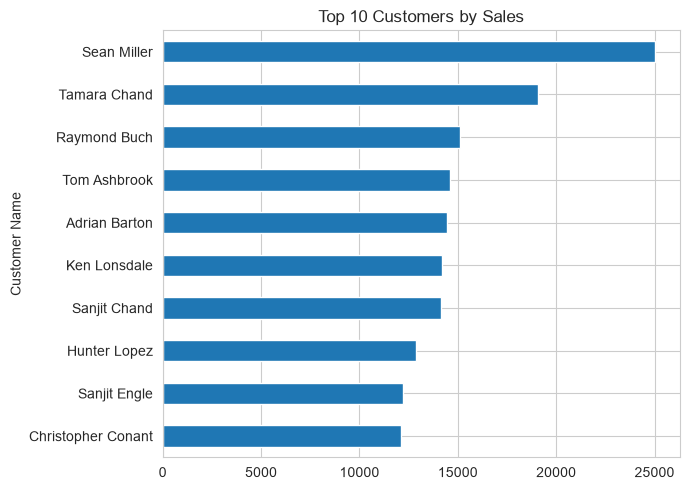

In [32]:
top_customers = df.groupby("Customer Name")["Sales"].sum().sort_values(ascending=False).head(10)
print(top_customers)

top_customers.plot(kind="barh", figsize=(7,5))
plt.title('Top 10 Customers by Sales')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('Top 10 Customsers by sales.png')
plt.show()

### 3.8 Sales & Profit by Region

             Sales    Profit
Region                      
West     758958.57  97265.98
East     606566.62  95834.90
Central  514804.02  63576.39
South    399947.04  30279.55


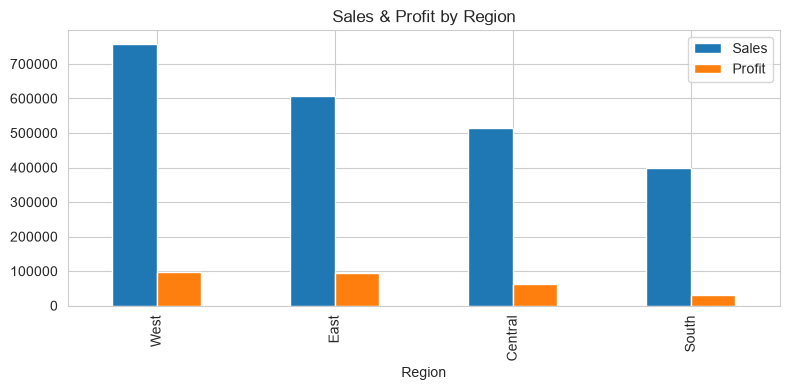

In [34]:
region_summary = df.groupby("Region")[["Sales","Profit"]].sum().sort_values("Sales", ascending=False)
print(region_summary)

region_summary.plot(kind="bar", figsize=(8,4))
plt.title('Sales & Profit by Region')
plt.tight_layout()
plt.savefig('Salea & Profit by Region.png')
plt.show()

### 3.9 Shipping time by Ship Mode

ShipMode
Same Day          0.044199
First Class       2.188605
Second Class      3.234351
Standard Class    5.008435
Name: ShipDays, dtype: float64


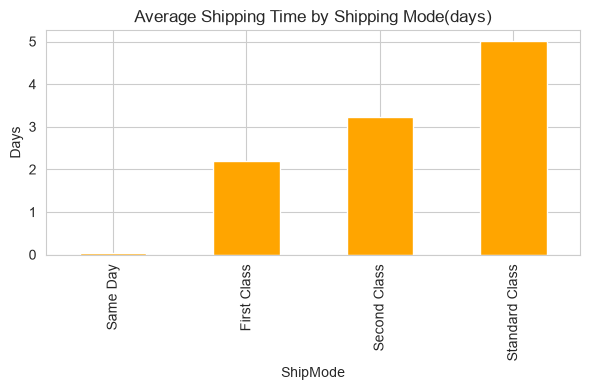

In [35]:
df["ShipDays"] = (df["ShipDate"] - df["OrderDate"]).dt.days

ship_summary = df.groupby("ShipMode")["ShipDays"].mean().sort_values()
print(ship_summary)

ship_summary.plot(kind="bar", figsize=(6,4), color="orange")
plt.title('Average Shipping Time by Shipping Mode(days)')
plt.ylabel("Days")
plt.tight_layout()
plt.savefig('Shipping time by shipping mode.png')
plt.show()

## 4. Key Findings & Recommendations

- **Category profitability:** Some categories generate strong sales but thin
  or negative margins once discounting is factored in; see the sub-category
  profit chart for the specific loss-making lines.
- **Discounting:** Profit clearly declines as discount level rises, and turns
  negative past a certain threshold, worth setting a discount cap.
- **Regional performance:** Sales and profit are not evenly distributed across
  regions; some regions may need discount-policy review if sales are high but
  profit is low.
- **Customer concentration:** A small group of top customers accounts for a
  disproportionate share of sales, worth a retention/loyalty focus.
- **Shipping:** Ship mode choice noticeably affects delivery time, which could
  be a factor in customer satisfaction analysis going forward.

### Next steps
- Segment-level RFM (Recency, Frequency, Monetary) analysis for customer
  retention targeting.
- Deeper investigation into the specific loss-making sub-categories and
  whether discount policy or cost structure is the driver.
- Extend the time-trend analysis to detect seasonality for demand planning.